## CIFAR-10 Image Classification: Shallow CNN vs Deep CNN vs MobileNetV2

Compare test accuracy, loss, training time, and generalization using the full CIFAR-10 training set.

## 1. Imports and Reproducibility

A fixed random seed is used so that the train/validation split and model initialization are reproducible as far as the execution environment allows.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, Sequential, Model
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import MobileNetV2

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

## 2. Load CIFAR-10

CIFAR-10 contains **60,000 RGB images of size 32 × 32 × 3** across 10 classes. The official split contains **50,000 training images** and **10,000 test images**. Each training class contains 5,000 images, so the dataset is already balanced.

In [ ]:
(x_train_full, y_train_full), (x_test, y_test) = cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

In [ ]:
print("Training images:", x_train_full.shape)

Training images: (50000, 32, 32, 3)


In [ ]:
print("Training labels:", y_train_full.shape)

Training labels: (50000, 1)


In [ ]:
print("Test images:", x_test.shape)

Test images: (10000, 32, 32, 3)


In [ ]:
print("Test labels:", y_test.shape)

Test labels: (10000, 1)


In [ ]:
print("Number of classes:", len(class_names))

Number of classes: 10


## 3. Exploratory Data Analysis (EDA)

For image data, EDA focuses on dimensions, data type, pixel range, class balance, data validity, and representative images. Because CIFAR-10 is a curated benchmark dataset, preprocessing is primarily normalization and validation rather than imputation or arbitrary outlier removal.

In [ ]:
print("Image dtype:", x_train_full.dtype)

Image dtype: uint8


In [ ]:
print("Image shape:", x_train_full.shape[1:])

Image shape: (32, 32, 3)


In [ ]:
print("Minimum pixel value:", x_train_full.min())

Minimum pixel value: 0


In [ ]:
print("Maximum pixel value:", x_train_full.max())

Maximum pixel value: 255


In [ ]:
print("Mean pixel value:", round(float(x_train_full.mean()), 2))

Mean pixel value: 120.71


In [ ]:
print("Pixel standard deviation:", round(float(x_train_full.std()), 2))

Pixel standard deviation: 64.15


In [ ]:
print("NaN values:", np.isnan(x_train_full).sum())

NaN values: 0


In [ ]:
print("Infinite values:", np.isinf(x_train_full).sum())

Infinite values: 0


In [ ]:
unique, counts = np.unique(y_train_full.flatten(), return_counts=True)
distribution = pd.DataFrame({
    "Class": [class_names[i] for i in unique],
    "Count": counts
})

distribution

,Class,Count
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


/tmp/ipykernel_15734/3974710573.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(class_names[int(y_train_full[i])])


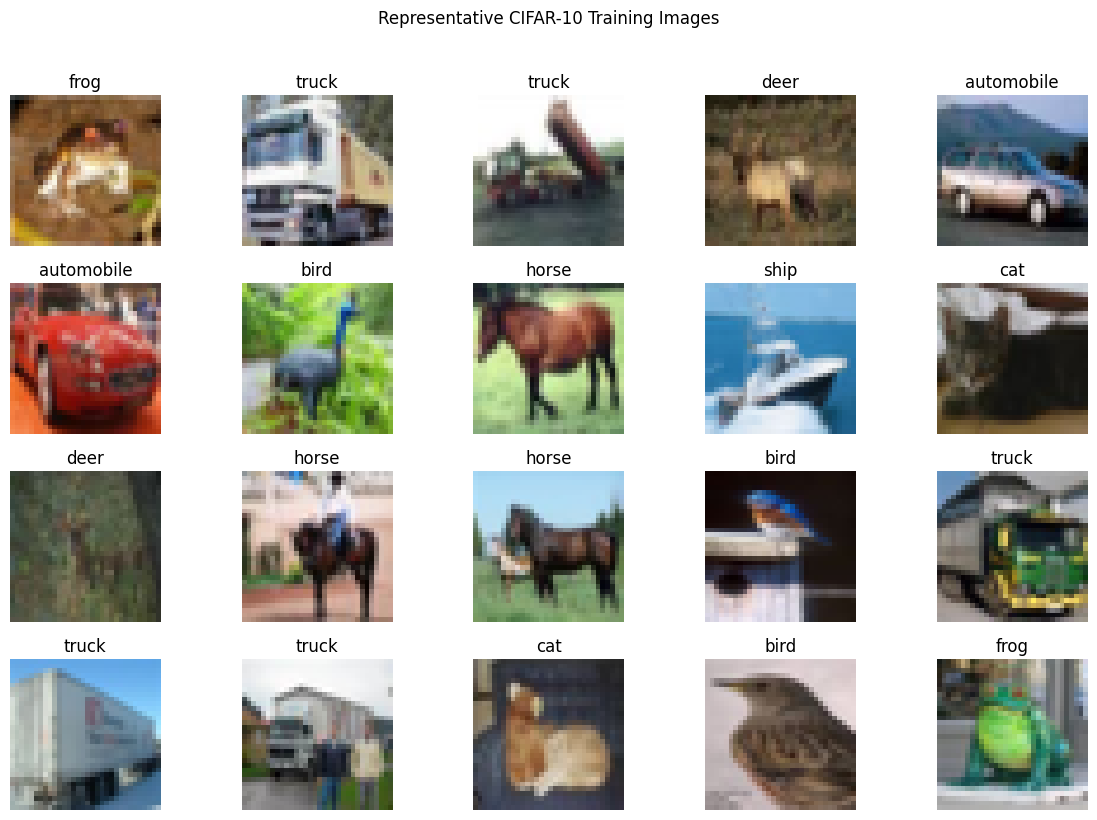

In [ ]:
plt.figure(figsize=(12, 8))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train_full[i])
    plt.title(class_names[int(y_train_full[i])])
    plt.axis("off")
plt.suptitle("Representative CIFAR-10 Training Images", y=1.02)
plt.tight_layout()
plt.show()

### EDA Findings

- The complete training set contains **50,000 images**, each with shape **32 × 32 × 3**.
- The test set contains **10,000 images** and is kept completely separate for final evaluation.
- Each class contains **5,000 training images**, confirming that the dataset is balanced.
- Pixel values are valid 8-bit values in the range **0–255**.
- No NaN or infinite values are present.
- No class weighting or resampling is required because the dataset is already balanced.

## 4. Train/Validation Split and Preprocessing

Use a stratified 45,000/5,000 train/validation split. Custom CNNs use [0,1] pixels; MobileNetV2 uses its [-1,1] input range.

In [ ]:
x_train_raw, x_val_raw, y_train, y_val = train_test_split(x_train_full,y_train_full,test_size=0.10,random_state=SEED,stratify=y_train_full)

y_train = y_train.flatten()
y_val = y_val.flatten()
y_test_flat = y_test.flatten()

x_train = x_train_raw.astype("float32") / 255.0
x_val = x_val_raw.astype("float32") / 255.0
x_test_custom = x_test.astype("float32") / 255.0

x_train_tl = x_train_raw
x_val_tl = x_val_raw
x_test_tl = x_test

print("Custom training set:", x_train.shape)

Custom training set: (45000, 32, 32, 3)


In [ ]:
print("Validation set:", x_val.shape)

Validation set: (5000, 32, 32, 3)


In [ ]:
print("Custom test set:", x_test_custom.shape)

Custom test set: (10000, 32, 32, 3)


In [ ]:
print("Transfer-learning training set:", x_train_tl.shape)

Transfer-learning training set: (45000, 32, 32, 3)


# Part 1 — Custom CNNs Trained From Scratch

Both models use the same augmentation, optimizer, callbacks, and data split. The main difference is depth.

### Training Setup (shared by both custom CNNs)
- **Augmentation** (training only): random horizontal flip and small shifts (up to 5%).
- **ReduceLROnPlateau:** halves the learning rate after 2 epochs without validation-loss improvement.
- **EarlyStopping:** stops after 4 epochs without improvement and restores the best weights.
- Up to **15 epochs**, batch size **64**.

In [ ]:
def make_callbacks():
    return [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
        )
    ]

MAX_CUSTOM_EPOCHS = 15
BATCH_SIZE = 64

data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

## 5. Shallow CNN

The Shallow CNN uses three convolutional stages followed by **Global Average Pooling (GAP)** and dense classification layers. Batch normalization improves training stability, while light augmentation reduces sensitivity to small image transformations. The model remains deliberately compact so it provides a meaningful baseline.

In [ ]:
shallow_model = Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(10, activation="softmax")
])

shallow_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

shallow_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,722 (436.41 KB)

 Trainable params: 111,274 (434.66 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
start_time = time.time()

shallow_history = shallow_model.fit(x_train,y_train,validation_data=(x_val, y_val),epochs=MAX_CUSTOM_EPOCHS,batch_size=BATCH_SIZE,verbose=1,callbacks=make_callbacks())

shallow_training_time = time.time() - start_time
shallow_test_loss, shallow_test_accuracy = shallow_model.evaluate(x_test_custom, y_test_flat, verbose=0)

print(f"Shallow CNN training time: {shallow_training_time:.2f} seconds")

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - accuracy: 0.4464 - loss: 1.5156 - val_accuracy: 0.4820 - val_loss: 1.4557 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 13ms/step - accuracy: 0.5571 - loss: 1.2326 - val_accuracy: 0.5360 - val_loss: 1.2801 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.5997 - loss: 1.1222 - val_accuracy: 0.5548 - val_loss: 1.2377 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6323 - loss: 1.0395 - val_accuracy: 0.5076 - val_loss: 1.3455 - learning_rate: 0.0010
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.6513 - loss: 0.9862 - val_accuracy: 0.5718 - val_loss: 1.2365 - learning_rate: 0.0010
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6706 - loss: 0.9390 - val_accuracy: 0.6418 - val_loss: 0.9890 - learning_rate: 0.0010
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.6819 - loss:

In [ ]:
print(f"Shallow CNN test accuracy: {shallow_test_accuracy:.4f}")

Shallow CNN test accuracy: 0.7479


In [ ]:
print(f"Shallow CNN test loss: {shallow_test_loss:.4f}")

Shallow CNN test loss: 0.7270


In [ ]:
print(f"Epochs completed: {len(shallow_history.history['loss'])}")

Epochs completed: 15


## 6. Deep CNN

The Deep CNN extends the same basic design to multiple convolutional blocks. Additional layers allow the network to learn a hierarchy of increasingly complex features. Batch normalization, dropout, and augmentation help control overfitting while preserving the intended depth comparison. `padding="same"` prevents repeated 3×3 convolutions from shrinking the spatial dimensions too aggressively.

In [ ]:
deep_model = Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.15),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(256, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(10, activation="softmax")
])

deep_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

deep_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 652,650 (2.49 MB)

 Trainable params: 651,242 (2.48 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [ ]:
start_time = time.time()

deep_history = deep_model.fit(x_train,y_train,validation_data=(x_val, y_val),epochs=MAX_CUSTOM_EPOCHS,batch_size=BATCH_SIZE,verbose=1,callbacks=make_callbacks())

deep_training_time = time.time() - start_time
deep_test_loss, deep_test_accuracy = deep_model.evaluate(x_test_custom, y_test_flat, verbose=0)

print(f"Deep CNN training time: {deep_training_time:.2f} seconds")

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.4800 - loss: 1.4261 - val_accuracy: 0.5332 - val_loss: 1.2757 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.6264 - loss: 1.0622 - val_accuracy: 0.5788 - val_loss: 1.2776 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6740 - loss: 0.9361
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.6888 - loss: 0.8955 - val_accuracy: 0.6194 - val_loss: 1.2771 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.7413 - loss: 0.7465 - val_accuracy: 0.7214 - val_loss: 0.7768 - learning_rate: 5.0000e-04
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.7581 - loss: 0.6977 - val_accuracy: 0.7768 - val_loss: 0.6250 - learning_rate: 5.0000e-04
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.77

In [ ]:
print(f"Deep CNN test accuracy: {deep_test_accuracy:.4f}")

Deep CNN test accuracy: 0.8366


In [ ]:
print(f"Deep CNN test loss: {deep_test_loss:.4f}")

Deep CNN test loss: 0.4798


In [ ]:
print(f"Epochs completed: {len(deep_history.history['loss'])}")

Epochs completed: 15


## 7. Training Curves — Custom CNNs

These curves are used to assess both learning and generalization. A model that achieves high training accuracy but substantially lower validation accuracy may be overfitting. The best custom architecture is therefore selected using measured validation/test behavior rather than depth alone.

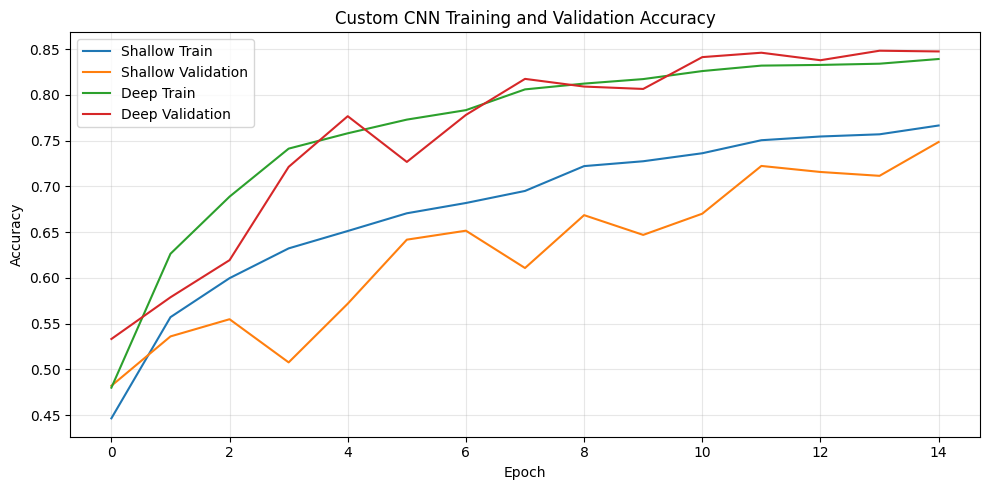

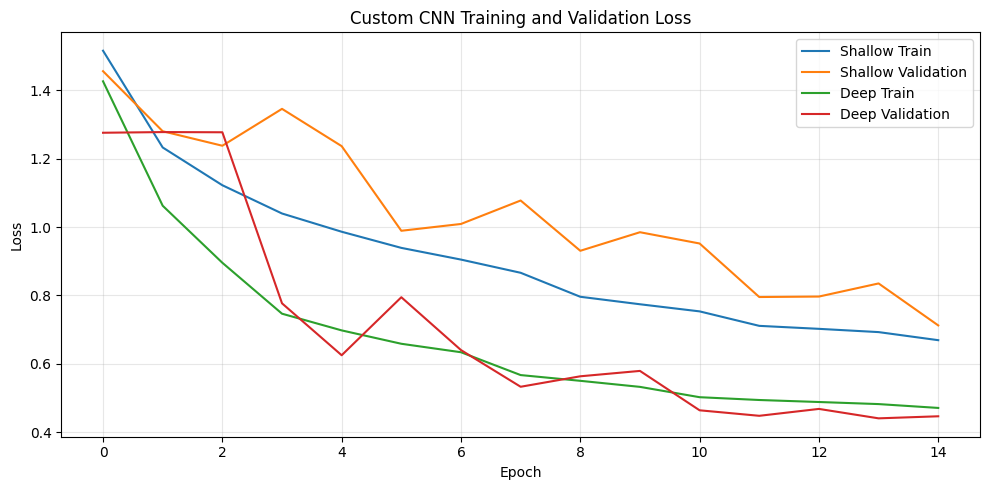

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(shallow_history.history["accuracy"], label="Shallow Train")
plt.plot(shallow_history.history["val_accuracy"], label="Shallow Validation")
plt.plot(deep_history.history["accuracy"], label="Deep Train")
plt.plot(deep_history.history["val_accuracy"], label="Deep Validation")
plt.title("Custom CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(shallow_history.history["loss"], label="Shallow Train")
plt.plot(shallow_history.history["val_loss"], label="Shallow Validation")
plt.plot(deep_history.history["loss"], label="Deep Train")
plt.plot(deep_history.history["val_loss"], label="Deep Validation")
plt.title("Custom CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Shallow vs Deep CNN

The Deep CNN achieved a test accuracy of **83.66%**, compared with **74.79%** for the Shallow CNN, representing an improvement of **8.87 percentage points**. This indicates that the additional convolutional depth provided greater representational capacity for the CIFAR-10 classification task.

The deeper architecture can learn hierarchical visual features: earlier convolutional layers detect relatively simple patterns such as edges and textures, while deeper layers combine these patterns into more complex shapes and class-specific representations.

The improvement in predictive performance came with a higher computational cost. The Deep CNN required approximately **267 seconds** of training compared with approximately **155 seconds** for the Shallow CNN. Therefore, increasing depth improved classification performance, but also increased training time and computational requirements.

Overall, the Deep CNN was the stronger custom architecture because its greater representational capacity resulted in significantly better test performance.

### Observations from the Training Logs

- **Shallow CNN:** training completed all **15 epochs**. Its final training and validation performance remained relatively close, indicating that the model was not strongly overfitting.
- **Deep CNN:** training also completed all **15 epochs** and achieved substantially higher accuracy than the Shallow CNN, showing the benefit of its greater representational capacity.

# Part 2 — Transfer Learning with MobileNetV2

MobileNetV2 is pretrained on ImageNet. Transfer learning starts from visual features learned on a much larger dataset instead of learning every feature from random initialization.

### Strategy
- Load MobileNetV2 without its original ImageNet classifier.
- Resize CIFAR-10 images from **32 × 32 to 96 × 96** inside the model.
- Convert pixel values from **[0, 255] to [-1, 1]**.
- Freeze the pretrained base and train a new CIFAR-10 classification head.
- Fine-tune only the final portion of the pretrained network at a low learning rate.

The fine-tuning stage is included as a controlled improvement: the majority of the pretrained representation remains fixed, while the last layers are allowed to adapt to CIFAR-10.

In [ ]:
base_model = MobileNetV2(weights="imagenet",include_top=False,input_shape=(96, 96, 3))
base_model.trainable = False

inputs = layers.Input(shape=(32, 32, 3))
x = layers.Resizing(96, 96)(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(10, activation="softmax")(x)

transfer_model = Model(inputs, outputs)
transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

transfer_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Why Resize CIFAR-10 Images and Use MobileNetV2 Preprocessing?

CIFAR-10 images have a native resolution of **32 × 32 pixels**, while the pretrained MobileNetV2 architecture is designed to work with larger image inputs. Therefore, the images are resized to **96 × 96 pixels** before being passed to the pretrained network.

Resizing does not create new image information, but it provides an input resolution that is more suitable for the pretrained feature-extraction architecture.

The preprocessing is also different from the custom CNNs. The custom CNNs use pixel values normalized to the **[0, 1]** range, whereas MobileNetV2 expects inputs approximately in the **[-1, 1]** range. Therefore, the transfer-learning pipeline applies:

**x' = (x / 127.5) - 1**

which converts the original pixel range [0, 255] to approximately [-1, 1].

### Train the Classifier Head
The base is frozen, so only the new head (**165,258 parameters**) is trained, for up to 5 epochs at a learning rate of 1e-3.

In [ ]:
TL_HEAD_EPOCHS = 5

start_time = time.time()

transfer_head_history = transfer_model.fit(
    x_train_tl,
    y_train,
    validation_data=(x_val_tl, y_val),
    epochs=TL_HEAD_EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
        )
    ]
)

head_training_time = time.time() - start_time

print(f"Frozen-base training time: {head_training_time:.2f} seconds")

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.7947 - loss: 0.6142 - val_accuracy: 0.8542 - val_loss: 0.4176 - learning_rate: 0.0010
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.8509 - loss: 0.4358 - val_accuracy: 0.8622 - val_loss: 0.3963 - learning_rate: 0.0010
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.8696 - loss: 0.3813 - val_accuracy: 0.8616 - val_loss: 0.3973 - learning_rate: 0.0010
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.8805 - loss: 0.3480 - val_accuracy: 0.8652 - val_loss: 0.3877 - learning_rate: 0.0010
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 19s 27ms/step - accuracy: 0.8920 - loss: 0.3134 - val_accuracy: 0.8700 - val_loss: 0.3868 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Frozen-base training time: 104.68 seconds


## Fine-Tuning the Transfer-Learning Model

After training the new classifier head, the final **30 layers** of MobileNetV2 are unfrozen for fine-tuning while the earlier layers remain frozen.

The purpose is to allow the deeper pretrained features to adapt to the CIFAR-10 dataset while preserving most of the general visual representations learned from ImageNet. Earlier layers generally learn more general features such as edges and textures, while deeper layers contain more task-specific representations.

A much smaller learning rate of **1e-5** is used during fine-tuning. This reduces the risk of making large updates that could destroy useful pretrained features. Fine-tuning therefore provides a balance between preserving pretrained knowledge and adapting the model to the new classification task.

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

transfer_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

start_time = time.time()

transfer_finetune_history = transfer_model.fit(
    x_train_tl,
    y_train,
    validation_data=(x_val_tl, y_val),
    epochs=3,
    batch_size=BATCH_SIZE,
    verbose=1,
    callbacks=[
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True, verbose=1
        )
    ]
)

finetune_training_time = time.time() - start_time
transfer_training_time = head_training_time + finetune_training_time

transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(x_test_tl, y_test_flat, verbose=0)

print(f"Fine-tuning time: {finetune_training_time:.2f} seconds")

Epoch 1/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 41ms/step - accuracy: 0.8205 - loss: 0.6070 - val_accuracy: 0.8744 - val_loss: 0.4039 - learning_rate: 1.0000e-05
Epoch 2/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.8691 - loss: 0.3897 - val_accuracy: 0.8804 - val_loss: 0.3763 - learning_rate: 1.0000e-05
Epoch 3/3
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.8938 - loss: 0.3063 - val_accuracy: 0.8820 - val_loss: 0.3687 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 3.
Fine-tuning time: 92.23 seconds


In [ ]:
print(f"Total transfer-learning time: {transfer_training_time:.2f} seconds")

Total transfer-learning time: 196.91 seconds


In [ ]:
print(f"Transfer-learning test accuracy: {transfer_test_accuracy:.4f}")

Transfer-learning test accuracy: 0.8735


In [ ]:
print(f"Transfer-learning test loss: {transfer_test_loss:.4f}")

Transfer-learning test loss: 0.3926


### Effect of Fine-Tuning

Fine-tuning allows the final **30 MobileNetV2 layers** to adapt their pretrained representations to CIFAR-10 while keeping the earlier layers frozen. The final MobileNetV2 model achieved **88.20% validation accuracy** and **87.35% test accuracy**.

The head-only model was not evaluated on the test set, so the final comparison with the test set is based on the fine-tuned model.

## 8. Transfer-Learning Training Curves

The head-training and fine-tuning histories are combined below so the full learning trajectory can be inspected. The fine-tuning phase uses a lower learning rate and updates only a small portion of the pretrained network.

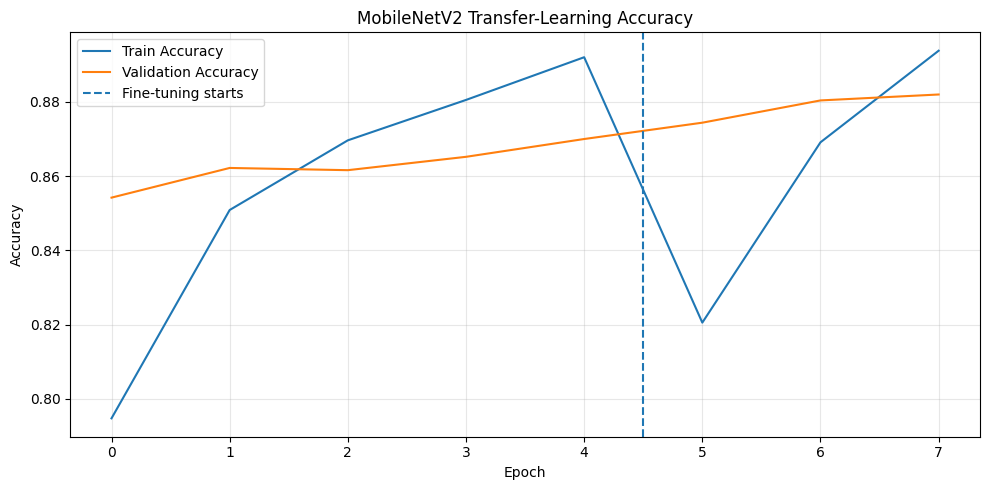

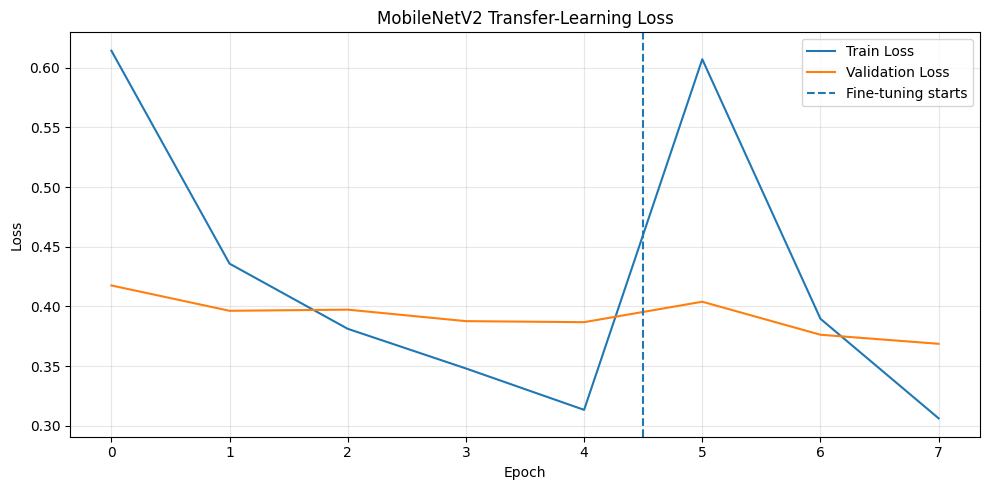

In [ ]:
transfer_acc = transfer_head_history.history["accuracy"] + transfer_finetune_history.history["accuracy"]
transfer_val_acc = transfer_head_history.history["val_accuracy"] + transfer_finetune_history.history["val_accuracy"]
transfer_loss = transfer_head_history.history["loss"] + transfer_finetune_history.history["loss"]
transfer_val_loss = transfer_head_history.history["val_loss"] + transfer_finetune_history.history["val_loss"]

plt.figure(figsize=(10, 5))
plt.plot(transfer_acc, label="Train Accuracy")
plt.plot(transfer_val_acc, label="Validation Accuracy")
plt.axvline(len(transfer_head_history.history["accuracy"]) - 0.5, linestyle="--", label="Fine-tuning starts")
plt.title("MobileNetV2 Transfer-Learning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(transfer_loss, label="Train Loss")
plt.plot(transfer_val_loss, label="Validation Loss")
plt.axvline(len(transfer_head_history.history["loss"]) - 0.5, linestyle="--", label="Fine-tuning starts")
plt.title("MobileNetV2 Transfer-Learning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Model Complexity

Accuracy is only one part of the comparison. Total parameters indicate overall model size, while trainable parameters indicate how many weights are actually optimized during the experiment. MobileNetV2 has many parameters overall, but the transfer-learning setup trains only a subset.

In [ ]:
def trainable_parameter_count(model):
    return int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))

def non_trainable_parameter_count(model):
    return int(np.sum([np.prod(v.shape) for v in model.non_trainable_weights]))

model_complexity = pd.DataFrame({
    "Model": [
        "Custom Shallow CNN",
        "Custom Deep CNN",
        "Transfer Learning (MobileNetV2)"
    ],
    "Total Parameters": [
        shallow_model.count_params(),
        deep_model.count_params(),
        transfer_model.count_params()
    ],
    "Trainable Parameters": [
        trainable_parameter_count(shallow_model),
        trainable_parameter_count(deep_model),
        trainable_parameter_count(transfer_model)
    ],
    "Non-trainable Parameters": [
        non_trainable_parameter_count(shallow_model),
        non_trainable_parameter_count(deep_model),
        non_trainable_parameter_count(transfer_model)
    ]
})

model_complexity

,Model,Total Parameters,Trainable Parameters,Non-trainable Parameters
0,Custom Shallow CNN,111722,111274,448
1,Custom Deep CNN,652650,651242,1408
2,Transfer Learning (MobileNetV2),2423242,1691658,731584


# Part 3 — Final Comparison

The table below is generated directly from the measured test-set results. The written interpretations that follow quote values from this run and should be updated if the notebook is rerun.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Custom Shallow CNN",
        "Custom Deep CNN",
        "Transfer Learning (MobileNetV2)"
    ],
    "Test Accuracy": [
        shallow_test_accuracy,
        deep_test_accuracy,
        transfer_test_accuracy
    ],
    "Test Loss": [
        shallow_test_loss,
        deep_test_loss,
        transfer_test_loss
    ],
    "Training Time (seconds)": [
        shallow_training_time,
        deep_training_time,
        transfer_training_time
    ]
})

results["Test Accuracy (%)"] = (results["Test Accuracy"] * 100).round(2)
results["Test Loss"] = results["Test Loss"].round(4)
results["Training Time (seconds)"] = results["Training Time (seconds)"].round(2)

comparison_table = results[[
    "Model", "Test Accuracy (%)", "Test Loss", "Training Time (seconds)"
]]

comparison_table

,Model,Test Accuracy (%),Test Loss,Training Time (seconds)
0,Custom Shallow CNN,74.79,0.7270,154.84
1,Custom Deep CNN,83.66,0.4798,267.24
2,Transfer Learning (MobileNetV2),87.35,0.3926,196.91


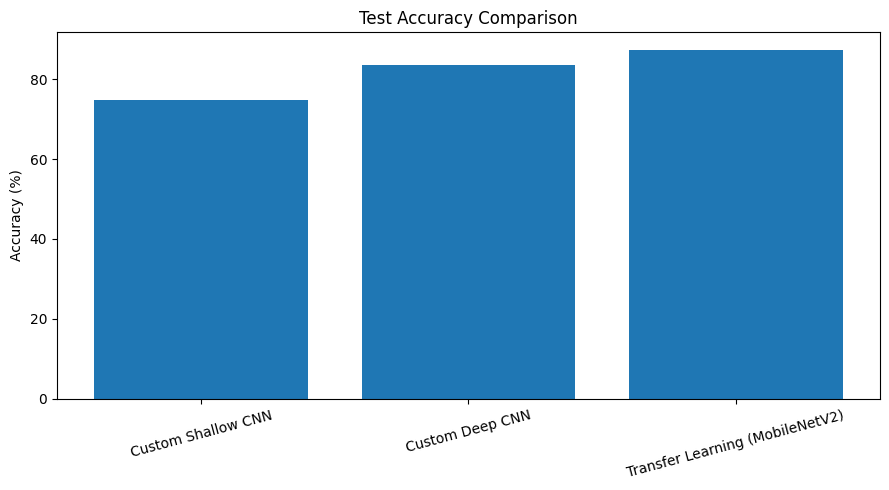

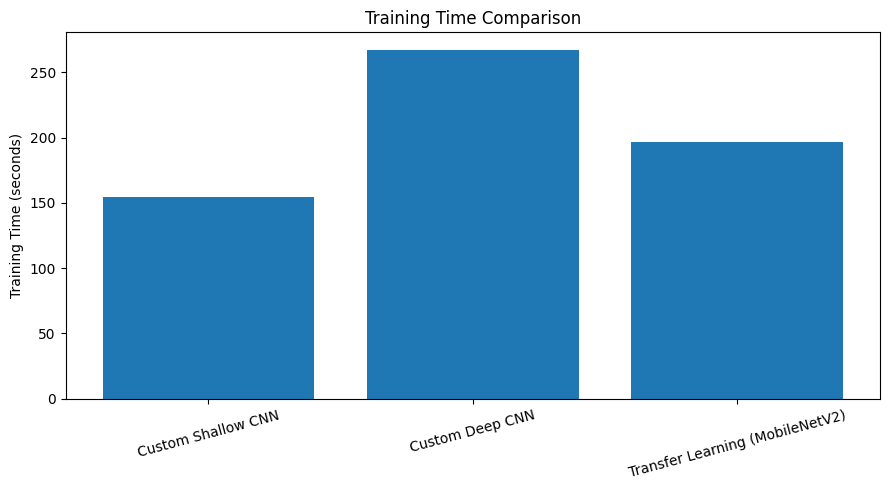

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Test Accuracy (%)"])
plt.title("Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Training Time (seconds)"])
plt.title("Training Time Comparison")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Fair Time Comparison

The models completed different numbers of epochs, so both total training time and time per epoch provide useful comparisons.

| Model | Epochs | Total time (s) | Time per epoch (s) |
|---|---:|---:|---:|
| Shallow CNN | 15 | 154.84 | 10.32 |
| Deep CNN | 15 | 267.24 | 17.82 |
| MobileNetV2 | 8 (5 head + 3 fine-tune) | 196.91 | 24.61 |

MobileNetV2 requires more time per epoch because it processes resized **96 × 96** images through a larger pretrained network. However, it completes fewer epochs, resulting in a total training time lower than the Deep CNN.

All timings were measured on a **GPU** runtime, so the absolute times are specific to the hardware used.

### Final Performance Interpretation

The final results show a clear improvement from the Shallow CNN to the Deep CNN and then to MobileNetV2.

The **Shallow CNN** achieved **74.79% test accuracy**, providing a baseline for a relatively simple architecture.

Increasing the network depth produced a substantial improvement. The **Deep CNN achieved 83.66% test accuracy**, which is **8.87 percentage points higher** than the Shallow CNN. This demonstrates the benefit of increased representational capacity for learning complex visual patterns.

The **MobileNetV2 transfer-learning model achieved the highest test accuracy of 87.35%** and the lowest test loss of **0.3926**. It therefore provided the strongest predictive performance among the three approaches.

There is also an important training-time trade-off. The Deep CNN required approximately **267 seconds**, while MobileNetV2 achieved higher accuracy in approximately **197 seconds**, about **26% less total training time** than the Deep CNN. The Shallow CNN remained the fastest at approximately **155 seconds**.

Overall, MobileNetV2 provided the strongest accuracy–efficiency trade-off in this experiment because its pretrained visual features allowed it to achieve the highest accuracy without the longer training time required by the Deep CNN.

## 10. Validation Accuracy Comparison

Validation accuracy is shown separately from final test accuracy because validation data was available during training, whereas the test set was held out for the final evaluation.

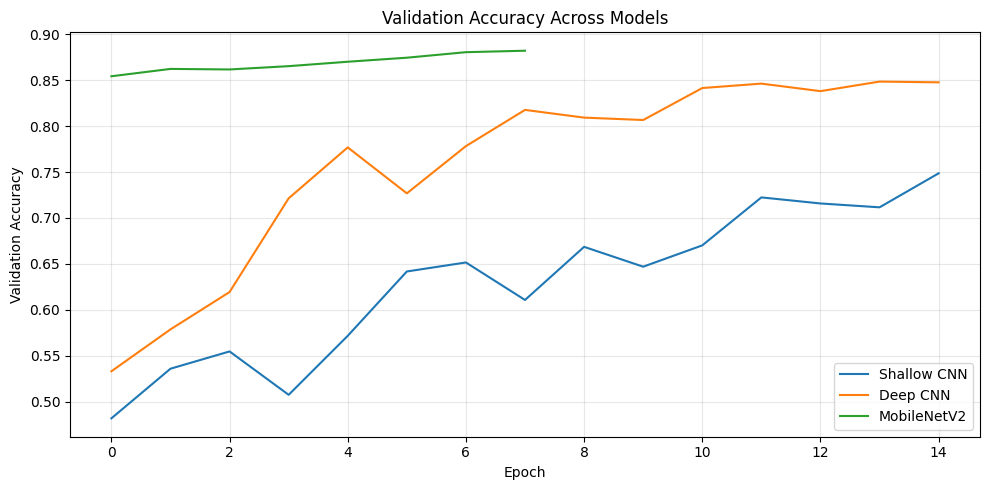

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(shallow_history.history["val_accuracy"], label="Shallow CNN")
plt.plot(deep_history.history["val_accuracy"], label="Deep CNN")
plt.plot(transfer_val_acc, label="MobileNetV2")
plt.title("Validation Accuracy Across Models")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Generalization Analysis

A useful secondary measure is the gap between the final training accuracy and validation accuracy. A large positive gap can indicate overfitting. The values below are calculated from the actual training histories.

In [ ]:
generalization = pd.DataFrame({
    "Model": ["Custom Shallow CNN", "Custom Deep CNN", "Transfer Learning (MobileNetV2)"],
    "Final Train Accuracy": [
        shallow_history.history["accuracy"][-1],
        deep_history.history["accuracy"][-1],
        transfer_acc[-1]
    ],
    "Final Validation Accuracy": [
        shallow_history.history["val_accuracy"][-1],
        deep_history.history["val_accuracy"][-1],
        transfer_val_acc[-1]
    ]
})
generalization["Generalization Gap"] = (generalization["Final Train Accuracy"] - generalization["Final Validation Accuracy"]).round(4)

generalization.round(4)

,Model,Final Train Accuracy,Final Validation Accuracy,Generalization Gap
0,Custom Shallow CNN,0.7666,0.7486,0.0180
1,Custom Deep CNN,0.8393,0.8476,-0.0083
2,Transfer Learning (MobileNetV2),0.8938,0.8820,0.0118


### Dataset Size Consideration

All three models used the same CIFAR-10 dataset: **45,000 training images, 5,000 validation images, and 10,000 test images**. Therefore, this experiment does not directly measure how performance changes with smaller datasets.

However, transfer learning can be advantageous when labeled data is limited because MobileNetV2 starts with visual features learned from ImageNet rather than learning all feature representations from scratch. In this experiment, the main transfer-learning advantage was demonstrated through **higher accuracy and a favorable training-time trade-off**, rather than through a reduced dataset size.

### Interpretation of Generalization Performance

The generalization results provide additional insight beyond test accuracy alone. The Shallow CNN has a relatively small train–validation gap of **1.80 percentage points**, while MobileNetV2 has a gap of only **1.18 points**.

The Deep CNN has a slightly negative gap of **-0.83 points** because its validation accuracy (**84.76%**) is slightly higher than its training accuracy (**83.93%**). This does not necessarily indicate a problem. During training, data augmentation and Dropout are active, making the training process intentionally more difficult. During validation, these regularization effects are disabled, so validation accuracy can sometimes be slightly higher.

Overall, the relatively small train–validation gaps suggest that the regularization techniques helped the models generalize rather than simply memorize the training data.

## 12. Detailed Test-Set Analysis

The best-performing model is selected from the final test-accuracy table. Its confusion matrix and classification report provide class-level evidence that complements the overall accuracy and loss metrics.

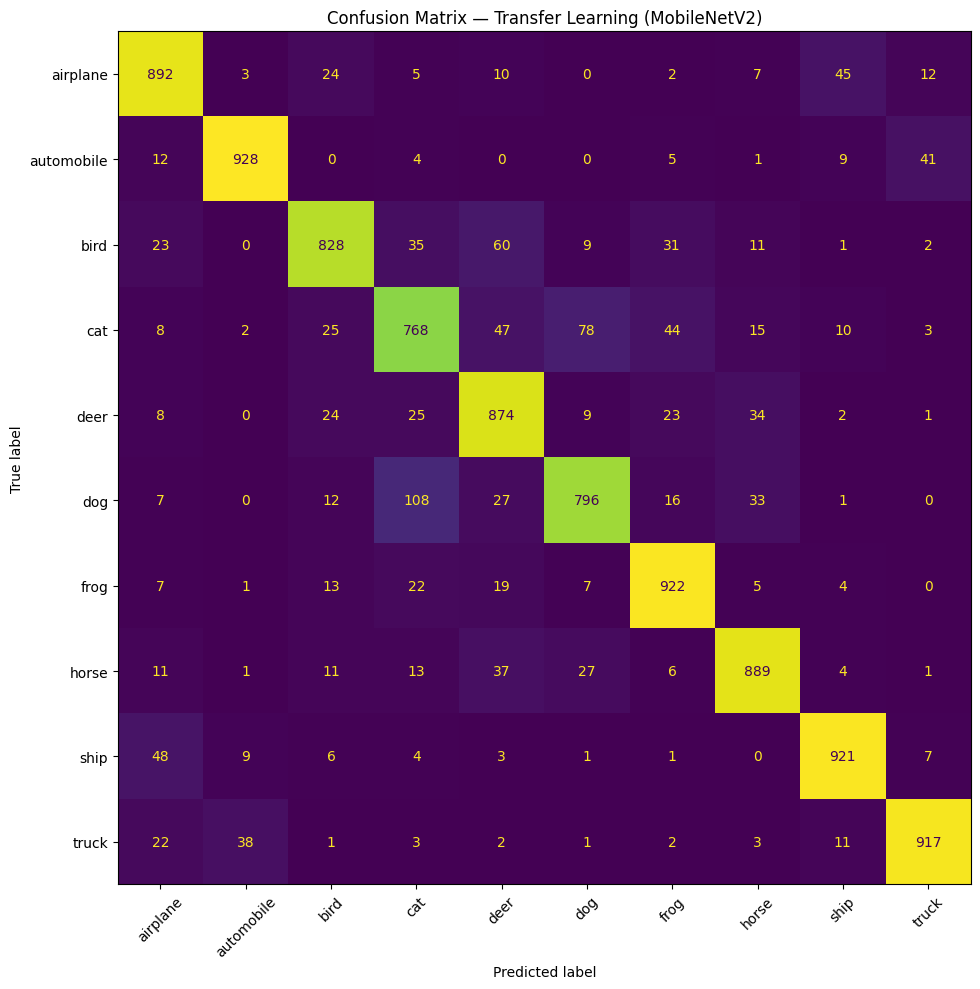

,precision,recall,f1-score,support
airplane,0.859,0.892,0.875,1000.000
automobile,0.945,0.928,0.936,1000.000
bird,0.877,0.828,0.852,1000.000
cat,0.778,0.768,0.773,1000.000
deer,0.810,0.874,0.841,1000.000
dog,0.858,0.796,0.826,1000.000
frog,0.876,0.922,0.899,1000.000
horse,0.891,0.889,0.890,1000.000
ship,0.914,0.921,0.917,1000.000
truck,0.932,0.917,0.924,1000.000


In [ ]:
best_model_name = results.loc[results["Test Accuracy (%)"].idxmax(), "Model"]

if best_model_name == "Custom Shallow CNN":
    best_model = shallow_model
    best_x_test = x_test_custom
elif best_model_name == "Custom Deep CNN":
    best_model = deep_model
    best_x_test = x_test_custom
else:
    best_model = transfer_model
    best_x_test = x_test_tl

best_predictions = best_model.predict(best_x_test, verbose=0)
y_pred = np.argmax(best_predictions, axis=1)
y_true = y_test_flat

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

classification_results = pd.DataFrame(classification_report(y_true,y_pred,target_names=class_names,output_dict=True,zero_division=0)).transpose()

classification_results.round(3)

### Interpretation of Class-Level Performance

The classification report shows that the MobileNetV2 model performs particularly well on visually distinctive classes. Classes such as **automobile, truck, ship, and frog** achieve relatively high F1-scores, indicating strong precision and recall.

In contrast, **cat and dog** are more challenging classes. These categories contain visually similar objects and can have substantial variation in pose, color, size, and background. The lower performance on these classes is therefore consistent with the difficulty of fine-grained visual classification in the CIFAR-10 dataset.

The confusion matrix provides further evidence of which classes are most frequently confused with one another. This class-level analysis is important because overall accuracy alone does not reveal whether errors are concentrated in particular categories.

## 13. Results-Driven Discussion

The statements below are generated from the actual values produced by the experiment. They should be read together with the comparison table, learning curves, and confusion matrix.

In [ ]:
shallow_acc = results.loc[results["Model"] == "Custom Shallow CNN", "Test Accuracy (%)"].iloc[0]
deep_acc = results.loc[results["Model"] == "Custom Deep CNN", "Test Accuracy (%)"].iloc[0]
tl_acc = results.loc[results["Model"] == "Transfer Learning (MobileNetV2)", "Test Accuracy (%)"].iloc[0]

shallow_time = results.loc[results["Model"] == "Custom Shallow CNN", "Training Time (seconds)"].iloc[0]
deep_time = results.loc[results["Model"] == "Custom Deep CNN", "Training Time (seconds)"].iloc[0]
tl_time = results.loc[results["Model"] == "Transfer Learning (MobileNetV2)", "Training Time (seconds)"].iloc[0]

custom_winner = "Deep CNN" if deep_acc > shallow_acc else "Shallow CNN"
accuracy_gain = abs(deep_acc - shallow_acc)

print(f"• Best overall model: {best_model_name} ({max(shallow_acc, deep_acc, tl_acc):.2f}% test accuracy).")





• Best overall model: Transfer Learning (MobileNetV2) (87.35% test accuracy).


In [ ]:
print(f"Among the custom CNNs, the {custom_winner} performed better by {accuracy_gain:.2f} percentage points.")

Among the custom CNNs, the Deep CNN performed better by 8.87 percentage points.


In [ ]:
print(f"Training time: Shallow={shallow_time:.2f}s, Deep={deep_time:.2f}s, MobileNetV2={tl_time:.2f}s.")

Training time: Shallow=154.84s, Deep=267.24s, MobileNetV2=196.91s.


### Key Findings

- The **Shallow CNN** is the fastest model, requiring about **155 s**, but it has the lowest test accuracy at **74.79%**.
- The **Deep CNN** improves test accuracy by **8.87 percentage points** to **83.66%**, but requires about **267 s** of training.
- **MobileNetV2 transfer learning** achieves the highest test accuracy (**87.35%**) and the lowest test loss (**0.3926**), while requiring about **197 s** of total training time.
- All three models use the same CIFAR-10 data: **45,000 training images, 5,000 validation images, and 10,000 test images**.
- Transfer learning provides the strongest accuracy–efficiency trade-off in this experiment.
- Ranking by test accuracy: **MobileNetV2 > Deep CNN > Shallow CNN**.
- Ranking by total training time: **Shallow CNN < MobileNetV2 < Deep CNN**.

# 14. Final Conclusion

This experiment compared three approaches to CIFAR-10 image classification: a Shallow CNN trained from scratch, a deeper CNN trained from scratch, and MobileNetV2 using transfer learning.

The **Shallow CNN achieved 74.79% test accuracy**, while the **Deep CNN improved performance to 83.66%**, demonstrating the benefit of increased network depth and representational capacity.

The **MobileNetV2 transfer-learning approach achieved the best result at 87.35% test accuracy and a test loss of 0.3926**. It also required approximately **197 seconds**, compared with **267 seconds** for the Deep CNN. Therefore, MobileNetV2 achieved the highest accuracy while requiring about **26% less total training time** than the Deep CNN.

Overall, the experiment shows that increasing CNN depth can substantially improve performance when training from scratch, while transfer learning can provide even stronger performance with a more favorable computational trade-off. **MobileNetV2 was the most effective approach among the three models evaluated.**